# Praktikum 2 - Klasifikasi Naive Bayes dengan Data Dummy

Pada percobaan ini digunakan data dummy (sintetis) yang dibuat dengan `make_classification` dari Scikit-Learn. Selanjutnya dibandingkan dua model Naive Bayes, yaitu **MultinomialNB** dan **GaussianNB**.

## Langkah 1 - Membuat Dataset Dummy

In [7]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di-encode (angka)
X, y = make_classification(
    n_samples=30, n_features=2, n_classes=2, n_informative=2,
    n_redundant=0, n_repeated=0, shuffle=False, random_state=42
)

# Secara default, make_classification menghasilkan nilai float
# Kita perlu mengubahnya dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka di belakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek hasil
print(X)
print(y)

[[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]
 [ 67  43]
 [ 36  54]
 [ 20  70]
 [122  70]
 [250  83]
 [ 50 142]
 [206 110]
 [115  84]
 [124  66]
 [150  85]
 [ 16  73]
 [ 46 113]
 [ 26  80]
 [ 18 114]
 [211 154]
 [ 53  66]
 [ 93 109]
 [175 172]
 [ 80  85]
 [111 125]
 [115 105]
 [ 66  92]
 [160  85]
 [ 53 106]
 [122  85]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Parameter yang digunakan pada fungsi `make_classification` adalah:

- `n_samples`: jumlah sampel yang diinginkan
- `n_features`: jumlah fitur yang digunakan
- `n_classes`: jumlah kelas
- `n_informative`: jumlah fitur yang memiliki korelasi dengan kelas
- `n_redundant`: jumlah fitur yang tidak memiliki korelasi dengan kelas
- `n_repeated`: jumlah fitur yang diulang
- `random_state`: seed agar data yang dihasilkan selalu sama (reproducible)

## Langkah 2 (Opsional) - Membuat Data Frame

Agar data lebih mudah dibaca, data dummy diubah menjadi DataFrame Pandas.

In [8]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat DataFrame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek DataFrame
df.head()

,Fitur 1,Fitur 2,Label
0,112,139,0
1,179,210,0
2,83,71,0
3,182,265,0
4,105,78,0


## Langkah 3 (Opsional) - Labeling

Label masih berupa encoding angka. Agar lebih mudah dibaca, label diubah menjadi bentuk kategorial.

In [9]:
# Definisikan nama label
labels = {
    1: 'Kelas A',
    0: 'Kelas B'
}

# Copy DataFrame untuk menyimpan DataFrame baru
# dengan label yang mudah dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
df_label['Label'] = df_label['Label'].map(labels)

# Cek DataFrame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,112,139,Kelas B
1,179,210,Kelas B
2,83,71,Kelas B
3,182,265,Kelas B
4,105,78,Kelas B


## Langkah 4 - Visualisasi Data

/tmp/ipykernel_6130/2236642212.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_6130/2236642212.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


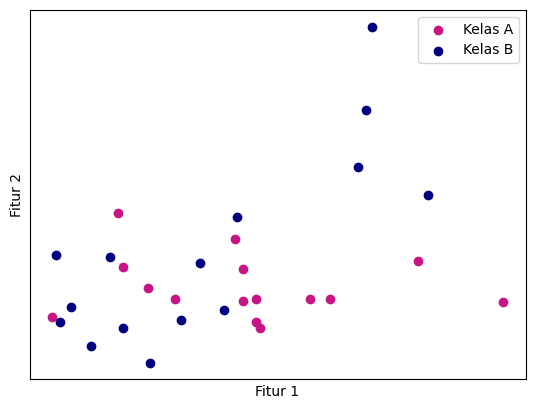

In [10]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.xticks([])
plt.yticks([])
plt.show()

## Langkah 5 - Model Multinomial Naive Bayes

Secara teori, MultinomialNB digunakan untuk fitur yang bersifat diskrit (misalnya jumlah kata pada klasifikasi teks). Pada percobaan ini model tersebut dicoba pada data kontinu **hanya sebagai pembelajaran**.

In [11]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inisiasi objek MultinomialNB
mnb = MultinomialNB()

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=30
)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metrik akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.8095238095238095
Hasil akurasi data test: 0.3333333333333333


## Langkah 6 - Model Gaussian Naive Bayes

GaussianNB lebih cocok digunakan untuk data kontinu karena mengasumsikan fitur berdistribusi normal.

In [12]:
from sklearn.naive_bayes import GaussianNB

# Inisiasi objek GaussianNB
gnb = GaussianNB()

# Gunakan split data training dan testing yang sama dengan model multinomial
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metrik akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.4444444444444444


## Analisis Hasil

1. MultinomialNB mengasumsikan fitur berupa nilai diskrit atau hasil counting. Penggunaannya pada data dummy yang telah dibulatkan dan dikalikan 100 hanya bertujuan untuk pembelajaran, bukan penerapan yang sepenuhnya sesuai asumsi model.
2. GaussianNB lebih sesuai secara teori untuk fitur kontinu karena memodelkan setiap fitur dengan distribusi normal pada masing-masing kelas.
3. Perbedaan akurasi data latih dan data uji perlu diperhatikan. Dengan hanya 30 sampel, model sangat mudah mengalami overfitting (akurasi latih tinggi tetapi akurasi uji rendah) atau underfitting.
4. Hasil dapat berbeda dari modul karena ditambahkan `random_state=42` pada `make_classification` agar data dummy yang dihasilkan selalu sama setiap kali kode dijalankan.